In [51]:
# Cell 1: imports and plotting style
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

import numpy as np

from typing import cast

PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

sns.set_theme(style="whitegrid", context="talk")

plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["figure.autolayout"] = True

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 120)

In [52]:
# Cell 2: use our data utilities
from src.data_loading import load_daily_clean_nuuksio

CLEAN_PATH = PROJECT_ROOT / "data" / "processed" / "nuuksio_daily_clean.csv"

df = load_daily_clean_nuuksio(CLEAN_PATH)

print("CLEAN SHAPE:", df.shape)
df.head()

CLEAN SHAPE: (3653, 10)


,datetime,date,station,tmax,tmin,tavg,prcp,dayofyear,dayofyear_sin,dayofyear_cos
0,2016-01-01 02:00:00,2016-01-01,Espoo Nuuksio,-4.3,-6.1,-5.6,0.2,1,0.000000,1.000000
1,2016-01-02 02:00:00,2016-01-02,Espoo Nuuksio,-6.0,-11.1,-9.5,0.4,2,0.017202,0.999852
2,2016-01-03 02:00:00,2016-01-03,Espoo Nuuksio,-8.6,-13.1,-10.3,4.5,3,0.034398,0.999408
3,2016-01-04 02:00:00,2016-01-04,Espoo Nuuksio,-7.5,-15.3,-13.4,0.0,4,0.051584,0.998669
4,2016-01-05 02:00:00,2016-01-05,Espoo Nuuksio,-15.2,-21.6,-19.6,0.1,5,0.068755,0.997634


In [53]:
# Cell 3: verify types and missingness in cleaned numeric columns
numeric_cols = ["tmax", "tmin", "tavg", "prcp"]

print(df[numeric_cols].describe().T)
print()
print("Missing per numeric column:")
print(df[numeric_cols].isna().sum())

       count      mean       std   min  25%  50%   75%   max
tmax  3653.0  9.998002  9.927471 -23.1  1.8  9.3  18.6  32.9
tmin  3653.0  2.625814  8.156347 -27.5 -2.3  2.0   9.3  22.0
tavg  3653.0  6.142896  8.705012 -25.5 -0.2  5.4  13.7  25.8
prcp  3653.0  2.163154  4.663192   0.0  0.0  0.1   2.2  53.5

Missing per numeric column:
tmax    0
tmin    0
tavg    0
prcp    0
dtype: int64


In [54]:
# Cell 3A: helper columns + pretty table printer
df = df.copy()
df["datetime"] = pd.to_datetime(df["datetime"])
df["year"] = df["datetime"].dt.year
df["month"] = df["datetime"].dt.month
df["month_name"] = df["datetime"].dt.strftime("%b")

def show_table(name, table, round_digits=2):
    out = table.copy()
    num_cols = out.select_dtypes(include="number").columns
    out[num_cols] = out[num_cols].round(round_digits)

    print(f"\n{name}")
    display(out)

    print("\nCopy/paste version:")
    try:
        print(out.to_markdown())
    except ImportError:
        print(out.to_string())

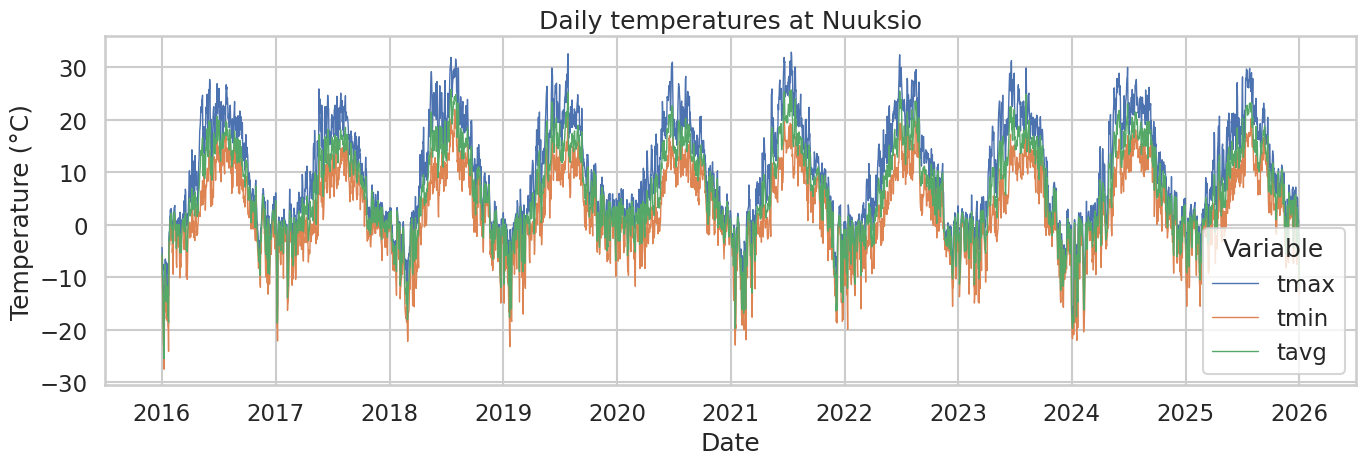

In [55]:
# Cell 4: time series plots for temperatures (Seaborn lineplot)
temp_long = df.melt(
    id_vars=["datetime"],
    value_vars=["tmax", "tmin", "tavg"],
    var_name="variable",
    value_name="temperature",
)

plt.figure(figsize=(14, 5))
sns.lineplot(
    data=temp_long,
    x="datetime",
    y="temperature",
    hue="variable",
    linewidth=1,
)
plt.title("Daily temperatures at Nuuksio")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend(title="Variable")
plt.savefig("../docs/figures/ch3_temp_timeseries.pdf", dpi=300, bbox_inches="tight")
plt.savefig("../docs/figures/ch3_temp_timeseries.png", dpi=300, bbox_inches="tight")
plt.show()

In [56]:
# Cell 4A: table summaries for temperature time series

temp_overall = (
    df[["tmin", "tavg", "tmax"]]
    .agg(["count", "mean", "median", "min", "max"])
    .T
)

temp_monthly = (
    df.groupby(["month", "month_name"], as_index=False)
    .agg(
        days=("datetime", "size"),
        mean_tmin=("tmin", "mean"),
        mean_tavg=("tavg", "mean"),
        mean_tmax=("tmax", "mean"),
        min_tmin=("tmin", "min"),
        max_tmax=("tmax", "max"),
    )
    .sort_values("month")
    .drop(columns="month")
    .set_index("month_name")
)

temp_yearly = (
    df.groupby("year", as_index=False)
    .agg(
        days=("datetime", "size"),
        mean_tmin=("tmin", "mean"),
        mean_tavg=("tavg", "mean"),
        mean_tmax=("tmax", "mean"),
        min_tmin=("tmin", "min"),
        max_tmax=("tmax", "max"),
    )
    .set_index("year")
)

show_table("Temperature summary (overall)", temp_overall)
show_table("Temperature summary by calendar month", temp_monthly)
show_table("Temperature summary by year", temp_yearly)


Temperature summary (overall)


,count,mean,median,min,max
tmin,3653.0,2.63,2.0,-27.5,22.0
tavg,3653.0,6.14,5.4,-25.5,25.8
tmax,3653.0,10.00,9.3,-23.1,32.9



Copy/paste version:
       count   mean  median   min   max
tmin  3653.0   2.63     2.0 -27.5  22.0
tavg  3653.0   6.14     5.4 -25.5  25.8
tmax  3653.0  10.00     9.3 -23.1  32.9

Temperature summary by calendar month


,days,mean_tmin,mean_tavg,mean_tmax,min_tmin,max_tmax
month_name,,,,,,
Jan,310,-6.76,-4.21,-1.97,-27.5,6.9
Feb,283,-6.11,-3.48,-1.03,-22.2,7.6
Mar,310,-4.00,-0.80,2.81,-20.6,12.3
Apr,300,-0.21,4.05,9.08,-8.7,21.5
May,310,5.14,10.84,16.92,-3.8,29.2
Jun,300,10.49,15.92,21.81,1.0,32.4
Jul,310,13.07,17.61,23.04,5.4,32.9
Aug,310,12.10,15.97,20.90,4.4,31.6
Sep,300,8.41,11.69,15.67,-1.4,26.2



Copy/paste version:
            days  mean_tmin  mean_tavg  mean_tmax  min_tmin  max_tmax
month_name                                                           
Jan          310      -6.76      -4.21      -1.97     -27.5       6.9
Feb          283      -6.11      -3.48      -1.03     -22.2       7.6
Mar          310      -4.00      -0.80       2.81     -20.6      12.3
Apr          300      -0.21       4.05       9.08      -8.7      21.5
May          310       5.14      10.84      16.92      -3.8      29.2
Jun          300      10.49      15.92      21.81       1.0      32.4
Jul          310      13.07      17.61      23.04       5.4      32.9
Aug          310      12.10      15.97      20.90       4.4      31.6
Sep          300       8.41      11.69      15.67      -1.4      26.2
Oct          310       3.34       5.84       8.57      -5.2      16.1
Nov          300      -0.56       1.53       3.43     -14.8      12.0
Dec          310      -3.91      -1.80       0.11     -18.7       7.2

,days,mean_tmin,mean_tavg,mean_tmax,min_tmin,max_tmax
year,,,,,,
2016,366,2.15,5.44,9.25,-27.5,27.7
2017,365,2.12,5.37,8.98,-22.1,25.9
2018,365,2.41,6.19,10.21,-22.2,31.9
2019,365,2.46,6.16,10.12,-23.2,32.6
2020,366,3.82,7.26,11.02,-11.7,31.0
2021,365,1.87,5.44,9.36,-22.9,32.9
2022,365,2.31,6.04,10.04,-19.9,32.4
2023,365,2.16,5.84,9.75,-16.4,31.3
2024,366,3.11,6.54,10.38,-22.0,30.0



Copy/paste version:
      days  mean_tmin  mean_tavg  mean_tmax  min_tmin  max_tmax
year                                                           
2016   366       2.15       5.44       9.25     -27.5      27.7
2017   365       2.12       5.37       8.98     -22.1      25.9
2018   365       2.41       6.19      10.21     -22.2      31.9
2019   365       2.46       6.16      10.12     -23.2      32.6
2020   366       3.82       7.26      11.02     -11.7      31.0
2021   365       1.87       5.44       9.36     -22.9      32.9
2022   365       2.31       6.04      10.04     -19.9      32.4
2023   365       2.16       5.84       9.75     -16.4      31.3
2024   366       3.11       6.54      10.38     -22.0      30.0
2025   365       3.85       7.16      10.87     -15.5      29.8


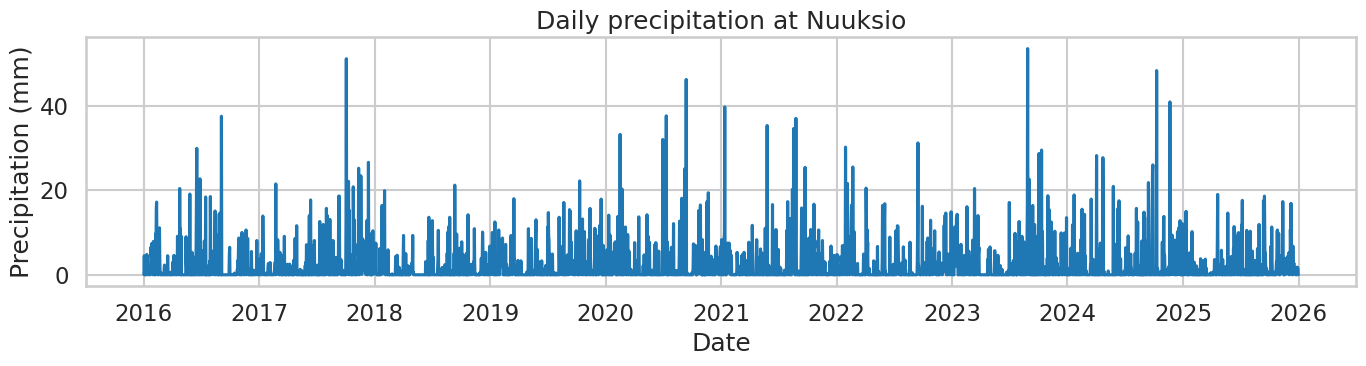

In [57]:
# Cell 5: time series plot for precipitation
plt.figure(figsize=(14, 4))
sns.lineplot(data=df, x="datetime", y="prcp", color="tab:blue")
plt.title("Daily precipitation at Nuuksio")
plt.xlabel("Date")
plt.ylabel("Precipitation (mm)")
plt.savefig("../docs/figures/ch3_prcp_timeseries.pdf", dpi=300, bbox_inches="tight")
plt.show()

In [58]:
# Cell 5A: table summaries for precipitation time series

precip_overall = pd.DataFrame(
    {
        "value": [
            df["prcp"].sum(),
            df["prcp"].mean(),
            df["prcp"].median(),
            df["prcp"].max(),
            (df["prcp"] > 0).sum(),
            100 * (df["prcp"] > 0).mean(),
        ]
    },
    index=[
        "total_prcp",
        "mean_daily_prcp",
        "median_daily_prcp",
        "max_daily_prcp",
        "rainy_days",
        "rainy_day_pct",
    ],
)

monthly_precip = (
    df.groupby(["year", "month", "month_name"], as_index=False)
    .agg(
        monthly_total_prcp=("prcp", "sum"),
        rainy_days=("prcp", lambda s: (s > 0).sum()),
        mean_daily_prcp=("prcp", "mean"),
        max_daily_prcp=("prcp", "max"),
    )
)

precip_monthly = (
    monthly_precip.groupby(["month", "month_name"], as_index=False)
    .agg(
        avg_monthly_total_prcp=("monthly_total_prcp", "mean"),
        avg_rainy_days=("rainy_days", "mean"),
        avg_mean_daily_prcp=("mean_daily_prcp", "mean"),
        avg_max_daily_prcp=("max_daily_prcp", "mean"),
    )
    .sort_values("month")
    .drop(columns="month")
    .set_index("month_name")
)

precip_yearly = (
    df.groupby("year", as_index=False)
    .agg(
        days=("datetime", "size"),
        total_prcp=("prcp", "sum"),
        mean_daily_prcp=("prcp", "mean"),
        median_daily_prcp=("prcp", "median"),
        max_daily_prcp=("prcp", "max"),
        rainy_days=("prcp", lambda s: (s > 0).sum()),
        rainy_day_pct=("prcp", lambda s: 100 * (s > 0).mean()),
    )
    .set_index("year")
)

show_table("Precipitation summary (overall)", precip_overall)
show_table("Precipitation summary by calendar month", precip_monthly)
show_table("Precipitation summary by year", precip_yearly)


Precipitation summary (overall)


,value
total_prcp,7902.00
mean_daily_prcp,2.16
median_daily_prcp,0.10
max_daily_prcp,53.50
rainy_days,1896.00
rainy_day_pct,51.90



Copy/paste version:
                     value
total_prcp         7902.00
mean_daily_prcp       2.16
median_daily_prcp     0.10
max_daily_prcp       53.50
rainy_days         1896.00
rainy_day_pct        51.90

Precipitation summary by calendar month


,avg_monthly_total_prcp,avg_rainy_days,avg_mean_daily_prcp,avg_max_daily_prcp
month_name,,,,
Jan,78.36,21.0,2.53,18.24
Feb,64.04,15.4,2.25,16.67
Mar,39.20,14.0,1.26,10.21
Apr,45.94,13.4,1.53,14.37
May,39.29,10.2,1.27,15.65
Jun,54.00,11.7,1.80,16.10
Jul,65.29,15.0,2.11,16.90
Aug,89.18,17.0,2.88,20.54
Sep,78.33,13.0,2.61,26.27



Copy/paste version:
            avg_monthly_total_prcp  avg_rainy_days  avg_mean_daily_prcp  avg_max_daily_prcp
month_name                                                                                 
Jan                          78.36            21.0                 2.53               18.24
Feb                          64.04            15.4                 2.25               16.67
Mar                          39.20            14.0                 1.26               10.21
Apr                          45.94            13.4                 1.53               14.37
May                          39.29            10.2                 1.27               15.65
Jun                          54.00            11.7                 1.80               16.10
Jul                          65.29            15.0                 2.11               16.90
Aug                          89.18            17.0                 2.88               20.54
Sep                          78.33            13.0         

,days,total_prcp,mean_daily_prcp,median_daily_prcp,max_daily_prcp,rainy_days,rainy_day_pct
year,,,,,,,
2016,366,739.4,2.02,0.0,37.5,177,48.36
2017,365,944.7,2.59,0.3,51.1,222,60.82
2018,365,492.0,1.35,0.0,21.2,163,44.66
2019,365,816.9,2.24,0.2,22.2,199,54.52
2020,366,939.6,2.57,0.1,46.2,188,51.37
2021,365,799.4,2.19,0.0,39.7,182,49.86
2022,365,766.8,2.10,0.1,31.2,190,52.05
2023,365,885.9,2.43,0.1,53.5,193,52.88
2024,366,863.2,2.36,0.0,48.3,178,48.63



Copy/paste version:
      days  total_prcp  mean_daily_prcp  median_daily_prcp  max_daily_prcp  rainy_days  rainy_day_pct
year                                                                                                 
2016   366       739.4             2.02                0.0            37.5         177          48.36
2017   365       944.7             2.59                0.3            51.1         222          60.82
2018   365       492.0             1.35                0.0            21.2         163          44.66
2019   365       816.9             2.24                0.2            22.2         199          54.52
2020   366       939.6             2.57                0.1            46.2         188          51.37
2021   365       799.4             2.19                0.0            39.7         182          49.86
2022   365       766.8             2.10                0.1            31.2         190          52.05
2023   365       885.9             2.43                0.1   

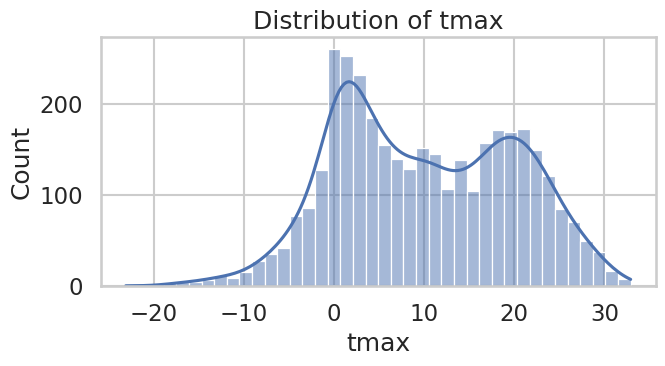

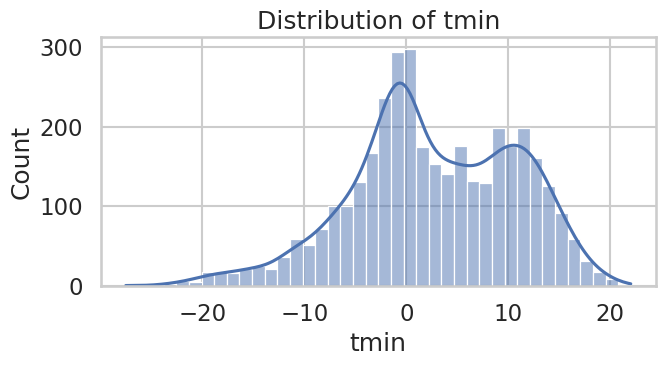

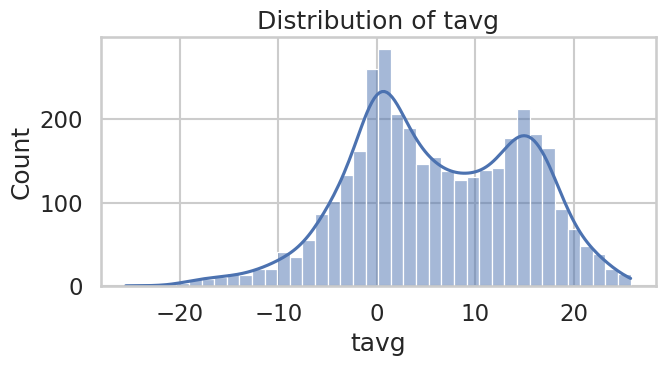

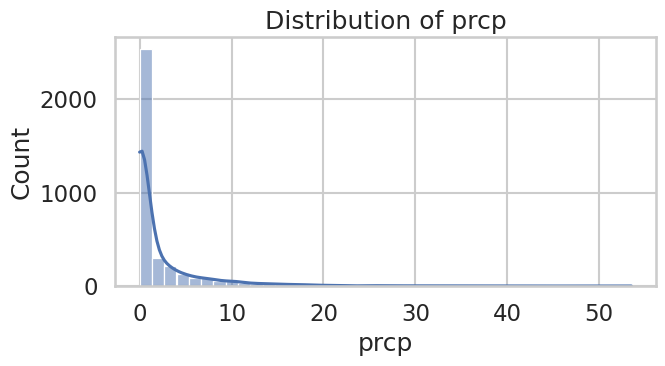

In [59]:
# Cell 6: histograms of numeric variables
for col in numeric_cols:
    plt.figure(figsize=(7, 4))
    sns.histplot(data=df, x=col, kde=True, bins=40)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.show()

In [60]:
# Cell 6A: distribution summary table for histogram variables

dist_summary = (
    df[numeric_cols]
    .describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99])
    .T
    .rename(
        columns={
            "1%": "p01",
            "5%": "p05",
            "25%": "p25",
            "50%": "p50",
            "75%": "p75",
            "95%": "p95",
            "99%": "p99",
        }
    )
)

dist_summary["missing"] = df[numeric_cols].isna().sum()
dist_summary["missing_pct"] = 100 * df[numeric_cols].isna().mean()
dist_summary["skew"] = df[numeric_cols].skew()

dist_summary = dist_summary[
    [
        "count",
        "missing",
        "missing_pct",
        "mean",
        "std",
        "min",
        "p01",
        "p05",
        "p25",
        "p50",
        "p75",
        "p95",
        "p99",
        "max",
        "skew",
    ]
]

show_table("Distribution summary for numeric variables", dist_summary)


Distribution summary for numeric variables


,count,missing,missing_pct,mean,std,min,p01,p05,p25,p50,p75,p95,p99,max,skew
tmax,3653.0,0,0.0,10.00,9.93,-23.1,-11.10,-4.50,1.8,9.3,18.6,25.80,29.60,32.9,0.05
tmin,3653.0,0,0.0,2.63,8.16,-27.5,-18.60,-11.30,-2.3,2.0,9.3,14.90,17.85,22.0,-0.31
tavg,3653.0,0,0.0,6.14,8.71,-25.5,-14.95,-7.44,-0.2,5.4,13.7,19.44,23.15,25.8,-0.12
prcp,3653.0,0,0.0,2.16,4.66,0.0,0.00,0.00,0.0,0.1,2.2,10.94,21.34,53.5,4.10



Copy/paste version:
       count  missing  missing_pct   mean   std   min    p01    p05  p25  p50   p75    p95    p99   max  skew
tmax  3653.0        0          0.0  10.00  9.93 -23.1 -11.10  -4.50  1.8  9.3  18.6  25.80  29.60  32.9  0.05
tmin  3653.0        0          0.0   2.63  8.16 -27.5 -18.60 -11.30 -2.3  2.0   9.3  14.90  17.85  22.0 -0.31
tavg  3653.0        0          0.0   6.14  8.71 -25.5 -14.95  -7.44 -0.2  5.4  13.7  19.44  23.15  25.8 -0.12
prcp  3653.0        0          0.0   2.16  4.66   0.0   0.00   0.00  0.0  0.1   2.2  10.94  21.34  53.5  4.10


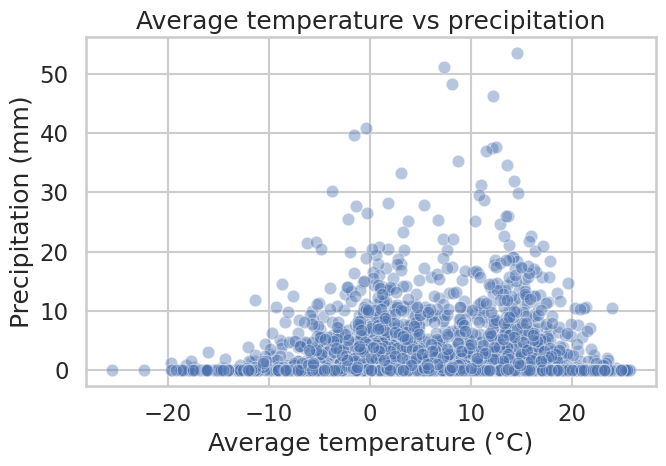

In [61]:
# Cell 7: scatter plot temperature vs precipitation
plt.figure(figsize=(7, 5))
sns.scatterplot(
    data=df,
    x="tavg",
    y="prcp",
    alpha=0.4,
)
plt.title("Average temperature vs precipitation")
plt.xlabel("Average temperature (°C)")
plt.ylabel("Precipitation (mm)")
plt.show()

In [62]:
# Cell 7A: table summaries for tavg vs prcp scatter plot

scatter_df = df.dropna(subset=["tavg", "prcp"]).copy()

scatter_df["tavg_bin"] = pd.cut(
    scatter_df["tavg"],
    bins=[-40, -20, -10, 0, 10, 20, 30, 40],
    right=False,
)

temp_precip_corr = pd.DataFrame(
    {"value": [scatter_df[["tavg", "prcp"]].corr().loc["tavg", "prcp"]]},
    index=["corr_tavg_prcp"],
)

temp_precip_by_bin = (
    scatter_df.groupby("tavg_bin", observed=False)
    .agg(
        days=("prcp", "size"),
        mean_prcp=("prcp", "mean"),
        median_prcp=("prcp", "median"),
        max_prcp=("prcp", "max"),
        rainy_day_pct=("prcp", lambda s: 100 * (s > 0).mean()),
    )
)

show_table("Temperature vs precipitation: correlation", temp_precip_corr)
show_table("Temperature vs precipitation by temperature band", temp_precip_by_bin)


Temperature vs precipitation: correlation


,value
corr_tavg_prcp,0.02



Copy/paste version:
                value
corr_tavg_prcp   0.02

Temperature vs precipitation by temperature band


,days,mean_prcp,median_prcp,max_prcp,rainy_day_pct
tavg_bin,,,,,
"[-40, -20)",2,0.00,0.0,0.0,0.00
"[-20, -10)",101,0.47,0.0,11.8,29.70
"[-10, 0)",831,1.96,0.2,40.9,57.16
"[0, 10)",1384,2.28,0.2,51.1,57.01
"[10, 20)",1184,2.50,0.0,53.5,47.80
"[20, 30)",151,0.75,0.0,10.7,23.84
"[30, 40)",0,NaN,NaN,NaN,NaN



Copy/paste version:
            days  mean_prcp  median_prcp  max_prcp  rainy_day_pct
tavg_bin                                                         
[-40, -20)     2       0.00          0.0       0.0           0.00
[-20, -10)   101       0.47          0.0      11.8          29.70
[-10, 0)     831       1.96          0.2      40.9          57.16
[0, 10)     1384       2.28          0.2      51.1          57.01
[10, 20)    1184       2.50          0.0      53.5          47.80
[20, 30)     151       0.75          0.0      10.7          23.84
[30, 40)       0        NaN          NaN       NaN            NaN


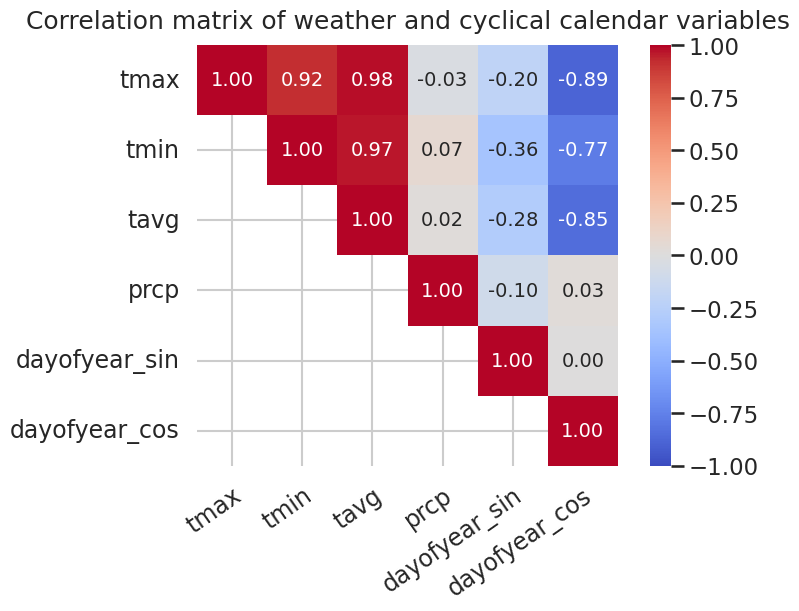

In [63]:
# Cell 8: correlation matrix among weather variables and cyclical calendar features
corr_cols = ["tmax", "tmin", "tavg", "prcp", "dayofyear_sin", "dayofyear_cos"]
corr = df[corr_cols].corr()

display_labels = ["tmax", "tmin", "tavg", "prcp", "dayofyear_sin", "dayofyear_cos"]

mask = np.tril(np.ones_like(corr, dtype=bool), k=-1)

fig, ax = plt.subplots(figsize=(8, 6), constrained_layout=True)

sns.heatmap(
    corr,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    square=True,
    ax=ax,
    annot_kws={"size": 14}
)

ax.set_xticklabels(display_labels, rotation=35, ha="right", rotation_mode="anchor", fontsize=17)
ax.set_yticklabels(display_labels, rotation=0, fontsize=17)

ax.set_title("Correlation matrix of weather and cyclical calendar variables", pad=12)
fig.savefig("../docs/figures/ch3_corr_matrix.pdf", dpi=300, bbox_inches="tight")
plt.show()

In [64]:
# Cell 8A: table versions of the correlation plot including cyclical calendar features

corr_cols = ["tmax", "tmin", "tavg", "prcp", "dayofyear_sin", "dayofyear_cos"]
corr_table = df[corr_cols].corr()

corr_pairs = pd.DataFrame(
    [
        {
            "var_1": a,
            "var_2": b,
            "correlation": df[[a, b]].dropna().corr().iloc[0, 1],
        }
        for i, a in enumerate(corr_cols)
        for b in corr_cols[i + 1 :]
    ]
).sort_values("correlation", key=lambda s: s.abs(), ascending=False).reset_index(drop=True)

show_table("Correlation matrix including cyclical calendar features", corr_table)
show_table("Pairwise correlations sorted by strength", corr_pairs)


Correlation matrix including cyclical calendar features


,tmax,tmin,tavg,prcp,dayofyear_sin,dayofyear_cos
tmax,1.00,0.92,0.98,-0.03,-0.20,-0.89
tmin,0.92,1.00,0.97,0.07,-0.36,-0.77
tavg,0.98,0.97,1.00,0.02,-0.28,-0.85
prcp,-0.03,0.07,0.02,1.00,-0.10,0.03
dayofyear_sin,-0.20,-0.36,-0.28,-0.10,1.00,0.00
dayofyear_cos,-0.89,-0.77,-0.85,0.03,0.00,1.00



Copy/paste version:
               tmax  tmin  tavg  prcp  dayofyear_sin  dayofyear_cos
tmax           1.00  0.92  0.98 -0.03          -0.20          -0.89
tmin           0.92  1.00  0.97  0.07          -0.36          -0.77
tavg           0.98  0.97  1.00  0.02          -0.28          -0.85
prcp          -0.03  0.07  0.02  1.00          -0.10           0.03
dayofyear_sin -0.20 -0.36 -0.28 -0.10           1.00           0.00
dayofyear_cos -0.89 -0.77 -0.85  0.03           0.00           1.00

Pairwise correlations sorted by strength


,var_1,var_2,correlation
0,tmax,tavg,0.98
1,tmin,tavg,0.97
2,tmax,tmin,0.92
3,tmax,dayofyear_cos,-0.89
4,tavg,dayofyear_cos,-0.85
5,tmin,dayofyear_cos,-0.77
6,tmin,dayofyear_sin,-0.36
7,tavg,dayofyear_sin,-0.28
8,tmax,dayofyear_sin,-0.20
9,prcp,dayofyear_sin,-0.10



Copy/paste version:
            var_1          var_2  correlation
0            tmax           tavg         0.98
1            tmin           tavg         0.97
2            tmax           tmin         0.92
3            tmax  dayofyear_cos        -0.89
4            tavg  dayofyear_cos        -0.85
5            tmin  dayofyear_cos        -0.77
6            tmin  dayofyear_sin        -0.36
7            tavg  dayofyear_sin        -0.28
8            tmax  dayofyear_sin        -0.20
9            prcp  dayofyear_sin        -0.10
10           tmin           prcp         0.07
11           prcp  dayofyear_cos         0.03
12           tmax           prcp        -0.03
13           tavg           prcp         0.02
14  dayofyear_sin  dayofyear_cos         0.00


In [65]:
# Cell 8B: selected correlations involving cyclical calendar features

corr_cols = ["tmax", "tmin", "tavg", "prcp", "dayofyear_sin", "dayofyear_cos"]
corr_table = df[corr_cols].corr()

selected_corr_rows = pd.DataFrame(
    [
        {
            "calendar_feature": cal_feat,
            "other_variable": other,
            "correlation": float(cast(float, corr_table.loc[cal_feat, other])),
        }
        for cal_feat in ["dayofyear_sin", "dayofyear_cos"]
        for other in ["tmax", "tmin", "tavg", "prcp"]
    ]
).sort_values(["calendar_feature", "correlation"], key=lambda s: s.abs() if s.name == "correlation" else s)

show_table("Selected correlations: cyclical calendar features vs weather variables", selected_corr_rows)


Selected correlations: cyclical calendar features vs weather variables


,calendar_feature,other_variable,correlation
7,dayofyear_cos,prcp,0.03
5,dayofyear_cos,tmin,-0.77
6,dayofyear_cos,tavg,-0.85
4,dayofyear_cos,tmax,-0.89
3,dayofyear_sin,prcp,-0.10
0,dayofyear_sin,tmax,-0.20
2,dayofyear_sin,tavg,-0.28
1,dayofyear_sin,tmin,-0.36



Copy/paste version:
  calendar_feature other_variable  correlation
7    dayofyear_cos           prcp         0.03
5    dayofyear_cos           tmin        -0.77
6    dayofyear_cos           tavg        -0.85
4    dayofyear_cos           tmax        -0.89
3    dayofyear_sin           prcp        -0.10
0    dayofyear_sin           tmax        -0.20
2    dayofyear_sin           tavg        -0.28
1    dayofyear_sin           tmin        -0.36


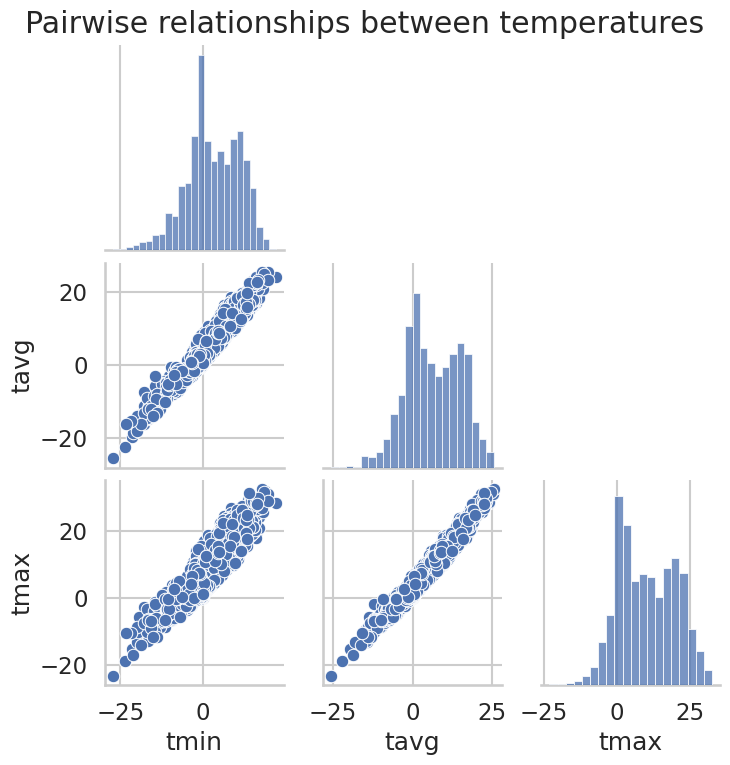

In [66]:
# Cell 9: pairplot for temperatures
sample = df.dropna(subset=["tmin", "tavg", "tmax"]).sample(
    n=min(1500, len(df)), random_state=0
)

sns.pairplot(
    data=sample,
    vars=["tmin", "tavg", "tmax"],
    corner=True,
    diag_kind="hist",
)
plt.suptitle("Pairwise relationships between temperatures", y=1.02)
plt.show()

In [67]:
# Cell 9A: optional summary tables for the pairplot sample

pairplot_summary = sample[["tmin", "tavg", "tmax"]].describe().T
pairplot_corr = sample[["tmin", "tavg", "tmax"]].corr()

show_table("Pairplot sample: summary statistics", pairplot_summary)
show_table("Pairplot sample: correlation matrix", pairplot_corr)


Pairplot sample: summary statistics


,count,mean,std,min,25%,50%,75%,max
tmin,1500.0,2.88,8.05,-27.2,-2.1,2.4,9.3,22.0
tavg,1500.0,6.33,8.59,-25.5,0.0,5.8,13.7,25.5
tmax,1500.0,10.16,9.78,-23.1,1.9,9.6,18.6,32.4



Copy/paste version:
       count   mean   std   min  25%  50%   75%   max
tmin  1500.0   2.88  8.05 -27.2 -2.1  2.4   9.3  22.0
tavg  1500.0   6.33  8.59 -25.5  0.0  5.8  13.7  25.5
tmax  1500.0  10.16  9.78 -23.1  1.9  9.6  18.6  32.4

Pairplot sample: correlation matrix


,tmin,tavg,tmax
tmin,1.00,0.97,0.92
tavg,0.97,1.00,0.98
tmax,0.92,0.98,1.00



Copy/paste version:
      tmin  tavg  tmax
tmin  1.00  0.97  0.92
tavg  0.97  1.00  0.98
tmax  0.92  0.98  1.00
